# Diplomatura en Ciencia de Datos, Aprendizaje Automático y sus Aplicaciones
## Evaluación de Arpendizaje Supervizado
### Grisel Britos, Sofía Perón Santana, Ana Luz Alabi Nassr, Paula Nieto, Felipe Andres Ávila
### Grupo 34

In [1]:
# Manejo de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

# Preprocesamiento
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold

# Modelos
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_graphviz
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
!pip install xgboost
from xgboost import XGBClassifier
from sklearn.svm import SVC

# Métricas y evaluación
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,classification_report

## 1. Análisis exploratorio
Comenzamos con el dataframe de entrenamiento.

In [2]:
df_train = pd.read_csv('https://raw.githubusercontent.com/DiploDatos/AprendizajeSupervisado/refs/heads/master/Pr%C3%A1ctico/diabetes_prediction_dataset_train-labeled.csv')
df_train.head(5)

,patient,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,20432,Male,4.0,0,0,never,19.28,3.5,155,0
1,49682,Female,50.0,0,0,former,27.32,5.7,159,0
2,73886,Female,43.0,0,0,never,21.54,4.5,145,0
3,53144,Male,64.0,0,0,current,28.22,6.0,130,0
4,98507,Male,10.0,0,0,No Info,15.46,6.1,140,0


In [3]:
print(df_train.shape)
print(df_train.describe())

(95000, 10)
             patient           age  hypertension  heart_disease           bmi  \
count   95000.000000  95000.000000  95000.000000   95000.000000  95000.000000   
mean    50016.501389     41.935269      0.075074       0.039463     27.320879   
std     28868.357071     22.514788      0.263512       0.194695      6.626335   
min         1.000000      0.080000      0.000000       0.000000     10.010000   
25%     25021.750000     24.000000      0.000000       0.000000     23.650000   
50%     50024.000000     43.000000      0.000000       0.000000     27.320000   
75%     75024.250000     60.000000      0.000000       0.000000     29.580000   
max    100000.000000     80.000000      1.000000       1.000000     95.690000   

        HbA1c_level  blood_glucose_level      diabetes  
count  95000.000000         95000.000000  95000.000000  
mean       5.527659           138.070537      0.085074  
std        1.070261            40.739962      0.278993  
min        3.500000           

In [4]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 95000 entries, 0 to 94999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient              95000 non-null  int64  
 1   gender               95000 non-null  object 
 2   age                  95000 non-null  float64
 3   hypertension         95000 non-null  int64  
 4   heart_disease        95000 non-null  int64  
 5   smoking_history      95000 non-null  object 
 6   bmi                  95000 non-null  float64
 7   HbA1c_level          95000 non-null  float64
 8   blood_glucose_level  95000 non-null  int64  
 9   diabetes             95000 non-null  int64  
dtypes: float64(3), int64(5), object(2)
memory usage: 7.2+ MB


In [5]:
df_train.isnull().sum()

patient                0
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

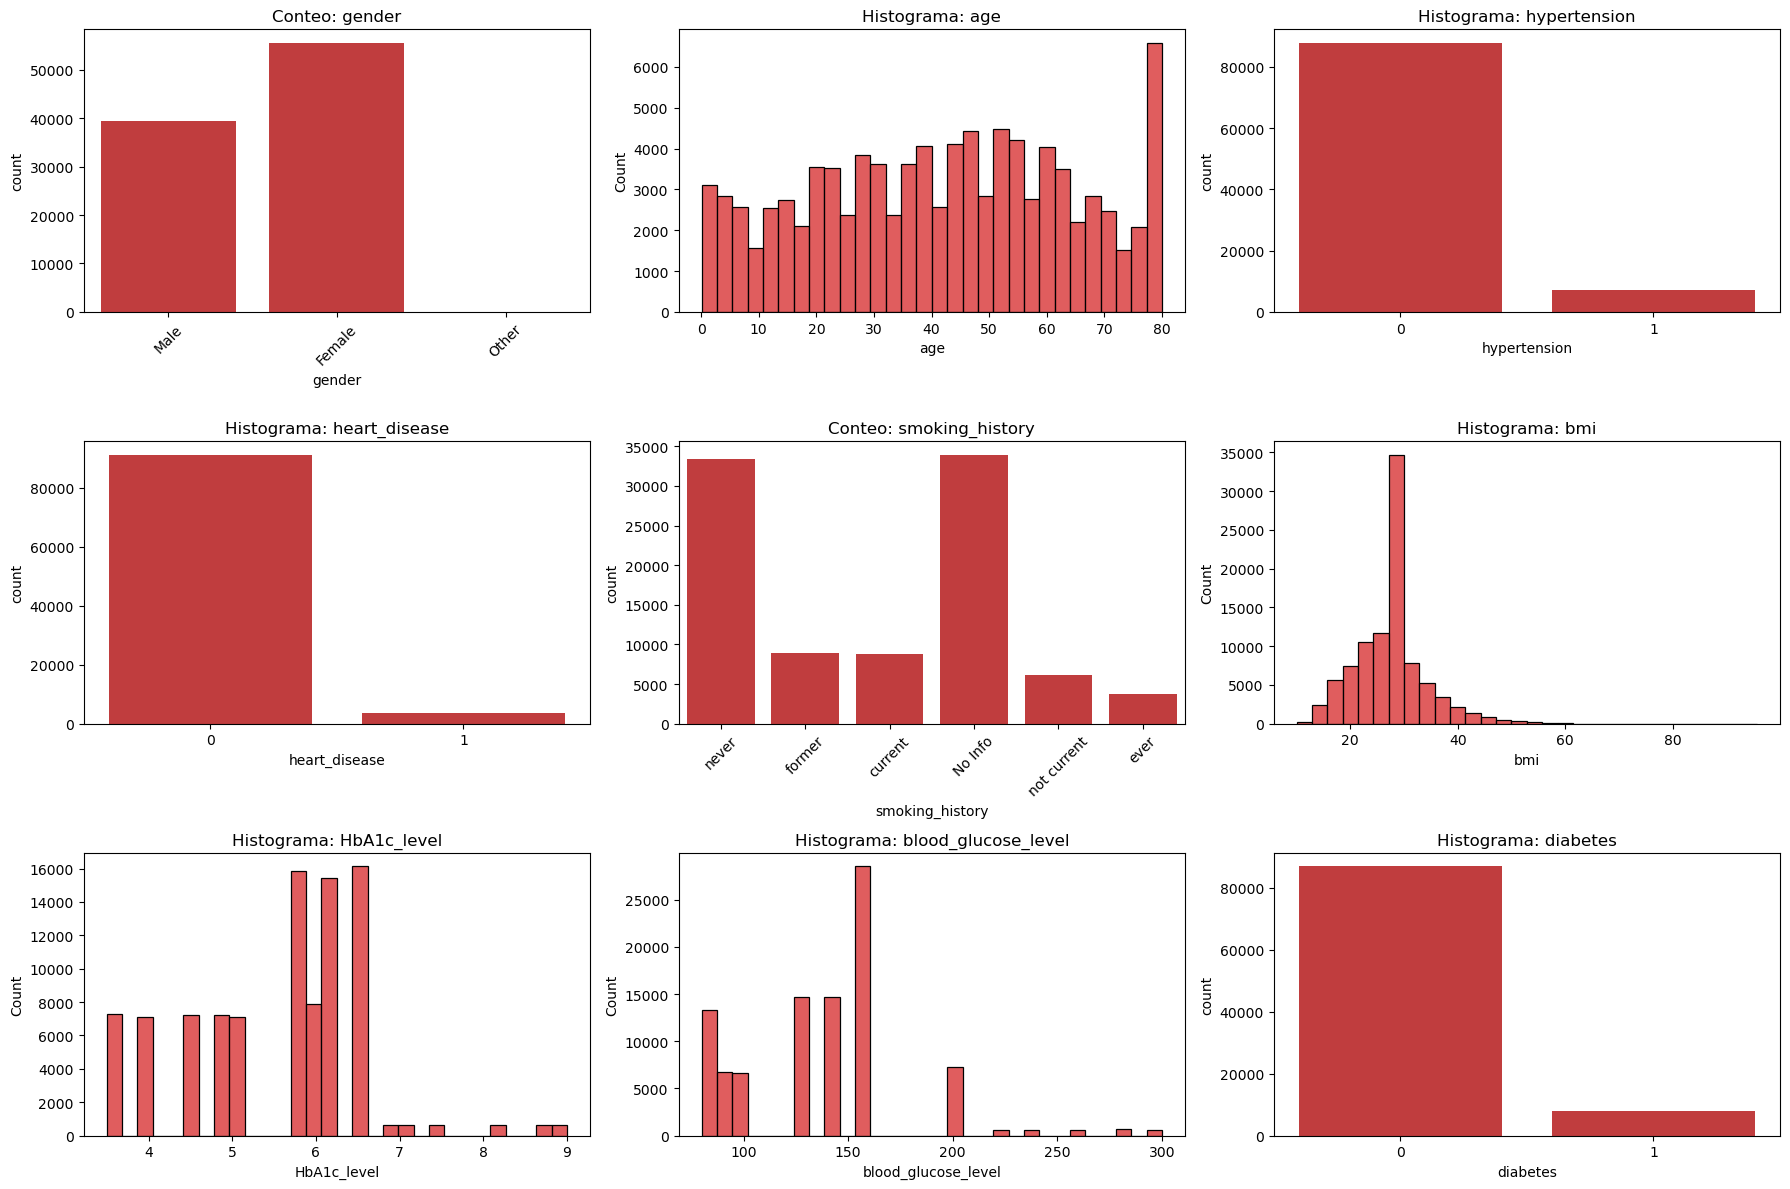

In [6]:
columnas = [
    'gender', 'age', 'hypertension', 'heart_disease',
    'smoking_history', 'bmi', 'HbA1c_level',
    'blood_glucose_level', 'diabetes'
]


fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 12))
axes = axes.flatten()

for i, col in enumerate(columnas):
    ax = axes[i]
    if col=='diabetes' or col=='hypertension' or col=='heart_disease':
        sns.countplot (x=col, data=df_train, ax=ax, color='tab:red')
        ax.set_title(f'Histograma: {col}')
    elif df_train[col].dtype == 'object':
        sns.countplot(x=col, data=df_train, ax=ax, color='tab:red')
        ax.set_title(f'Conteo: {col}')
        ax.tick_params(axis='x', rotation=45)
    else:
        sns.histplot(df_train[col], kde=False, bins=30, ax=ax,color='tab:red')
        ax.set_title(f'Histograma: {col}')

plt.tight_layout()
plt.show()

En el análisis exploratorio observamos que no existen valores faltantes ni outliers en el conjunto de datos. Sin embargo, será necesario convertir las variables categóricas utilizando LabelEncoder para poder procesarlas adecuadamente. Además vemos que las clases de diabetes están desbalanceadas por lo que vamos a balancear las clases submuestreando la clase mayoritaria para que tenga el mismo tamaño que la clase minoritaria.

In [7]:
#Variables Categóricas
df_train['gender'] = LabelEncoder().fit_transform(df_train['gender'].astype(str))
df_train['smoking_history'] = LabelEncoder().fit_transform(df_train['smoking_history'].astype(str))

# Separar clases
df_train_major = df_train[df_train['diabetes'] == 0]
df_train_minor = df_train[df_train['diabetes'] == 1]

# Submuestreo aleatorio de la clase mayoritaria para que tenga el mismo tamaño que la minoritaria
df_train_major_sample = df_train_major.sample(n=len(df_train_minor), random_state=42)

# Concatenar la clase minoritaria completa con la muestra balanceada de la mayoritaria
df_train_balanced = pd.concat([df_train_major_sample, df_train_minor]).sample(frac=1, random_state=42)

# Verificar el balanceo
print(df_train_balanced['diabetes'].value_counts())

diabetes
0    8082
1    8082
Name: count, dtype: int64


Preparamos el dataframe para los modelos de aprendizaje supervisado.

In [8]:
X = df_train_balanced.drop('diabetes', axis=1)
y = df_train_balanced['diabetes']
patientId = X.patient
X.drop('patient',axis=1,inplace=True)

print(X.columns)

Index(['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history',
       'bmi', 'HbA1c_level', 'blood_glucose_level'],
      dtype='object')


In [9]:
x_names = X.columns
X = StandardScaler().fit_transform(X)
X = pd.DataFrame(X, columns=x_names)
X.head(5)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level
0,-0.885832,-2.071754,-0.425107,-0.314039,1.409672,-2.122852,0.343374,-0.591755
1,-0.885832,0.628698,-0.425107,-0.314039,0.856427,-0.286672,0.031560,-0.152402
2,1.127184,0.256222,-0.425107,-0.314039,0.856427,0.904691,0.265420,-0.152402
3,-0.885832,-0.488731,-0.425107,-0.314039,-1.356552,-0.286672,-0.046394,-0.416014
4,1.127184,0.954614,-0.425107,-0.314039,1.409672,-0.682447,-0.046394,-1.470462


In [10]:
X_train, X_val, y_train, y_val = train_test_split(X, y, train_size=0.8, random_state = 8)

Continuamos con el dataframe de testeo.

In [11]:
df_test = pd.read_csv('https://raw.githubusercontent.com/DiploDatos/AprendizajeSupervisado/refs/heads/master/Pr%C3%A1ctico/diabetes_prediction_dataset_test.csv')
df_test.head(5)

,patient,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,49267,Male,53.0,0,0,never,31.99,4.5,126,NaN
1,82280,Female,22.0,0,0,never,25.96,6.6,130,NaN
2,33216,Female,37.0,0,0,never,22.24,6.2,126,NaN
3,94551,Female,29.0,0,0,not current,31.01,5.0,80,NaN
4,43760,Male,30.0,0,0,ever,28.66,6.6,100,NaN


In [12]:
print(df_test.shape)
print(df_test.describe())

(5000, 10)
            patient          age  hypertension  heart_disease          bmi  \
count   5000.000000  5000.000000   5000.000000    5000.000000  5000.000000   
mean   49696.473600    40.947016      0.070600       0.038600    27.318644   
std    28855.568156    22.537466      0.256181       0.192659     6.832943   
min        7.000000     0.160000      0.000000       0.000000    10.620000   
25%    24720.750000    23.000000      0.000000       0.000000    23.410000   
50%    49522.500000    41.000000      0.000000       0.000000    27.320000   
75%    74686.000000    59.000000      0.000000       0.000000    29.632500   
max    99970.000000    80.000000      1.000000       1.000000    88.760000   

       HbA1c_level  blood_glucose_level  diabetes  
count  5000.000000          5000.000000       0.0  
mean      5.524620           137.821000       NaN  
std       1.078559            40.101933       NaN  
min       3.500000            80.000000       NaN  
25%       4.800000        

In [13]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient              5000 non-null   int64  
 1   gender               5000 non-null   object 
 2   age                  5000 non-null   float64
 3   hypertension         5000 non-null   int64  
 4   heart_disease        5000 non-null   int64  
 5   smoking_history      5000 non-null   object 
 6   bmi                  5000 non-null   float64
 7   HbA1c_level          5000 non-null   float64
 8   blood_glucose_level  5000 non-null   int64  
 9   diabetes             0 non-null      float64
dtypes: float64(4), int64(4), object(2)
memory usage: 390.8+ KB


In [14]:
# Preprocesamiento
df_test['gender'] = LabelEncoder().fit_transform(df_test['gender'].astype(str))
df_test['smoking_history'] = LabelEncoder().fit_transform(df_test['smoking_history'].astype(str))

# Separar variables
Y_test = df_test['diabetes'] 
PatientId_test = df_test['patient']
X_test = df_test.drop(['patient', 'diabetes'], axis=1) 

# Escalar
cols = X_test.columns
X_test = StandardScaler().fit_transform(X_test)
X_test = pd.DataFrame(X_test, columns=cols)

X_test.head(5)

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level
0,1.216115,0.534851,-0.275614,-0.200374,0.989602,0.683720,-0.950085,-0.294803
1,-0.819565,-0.840774,-0.275614,-0.200374,0.989602,-0.198857,0.997153,-0.195048
2,-0.819565,-0.175149,-0.275614,-0.200374,0.989602,-0.743333,0.626250,-0.294803
3,-0.819565,-0.530149,-0.275614,-0.200374,1.517446,0.540283,-0.486457,-1.441995
4,1.216115,-0.485774,-0.275614,-0.200374,-0.066086,0.196327,0.997153,-0.943216


## 2. Perceptrón

In [15]:
models = [
    ("Perceptrón", Perceptron(max_iter=1000, tol=1e-3, random_state=42)),
    ("MLP (Logistic 32-16)", MLPClassifier(hidden_layer_sizes=(32, 16), activation='logistic', max_iter=300, random_state=42)),
    ("MLP (ReLU 32-16)", MLPClassifier(hidden_layer_sizes=(32, 16), activation='relu', max_iter=300, random_state=42))
]

trained_models = []
recall_scores = []

for name, model in models:
    print(f"\n{name}")
    model.fit(X_train, y_train)

    y_pred_train = model.predict(X_train)
    recall_train = recall_score(y_train, y_pred_train)
    print(f"Recall train {name}: {recall_train * 100:.2f}%")

    y_pred_val = model.predict(X_val)
    recall_val = recall_score(y_val, y_pred_val)
    print(f"Recall test {name}: {recall_val * 100:.2f}%")

    trained_models.append(model)
    recall_scores.append(recall_val * 100)


Perceptrón
Recall train Perceptrón: 86.35%
Recall test Perceptrón: 85.18%

MLP (Logistic 32-16)


C:\Users\pc\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Recall train MLP (Logistic 32-16): 92.04%
Recall test MLP (Logistic 32-16): 91.68%

MLP (ReLU 32-16)
Recall train MLP (ReLU 32-16): 93.37%
Recall test MLP (ReLU 32-16): 90.79%


Se observa en una primera inspección que el mejor modelo es el MLP (Logistic 64-32), así que realizamos el gridsearch sobre esta arquitectura.

In [16]:
# #GridSearch

# mlp = MLPClassifier(random_state=42, max_iter=500)

# # Defino la grilla de parámetros para probar
# param_grid = {
#     'hidden_layer_sizes': [(64, 32), (128,64), (64, 32, 8)], 
#     #'activation': ['logistic'],  ya sabemos que logistic es mejor
#     'alpha': [0.0001, 0.001, 0.01],  
#     'learning_rate_init': [0.001, 0.01, 0.1],
#     'solver': ['adam'],    
# }

# # Creo el GridSearch usando recall como métrica principal
# grid = GridSearchCV(
#     mlp,
#     param_grid,
#     scoring='recall',
#     cv=5,
#     n_jobs=-1,
#     verbose=2
# )

# grid.fit(X_train, y_train)

# print("Mejores parámetros encontrados:", grid.best_params_)

# print(f"Mejor recall CV: {grid.best_score_:.4f}")

Los hiperparámetros que definen al mejor modelo son :
                                                    hidden_layer_sizes=(128, 64),
                                                        activation='logistic',
                                                        max_iter=500,
                                                        random_state=42,
                                                        alpha=0.001,
                                                        learning_rate_init=0.1,
                                                        solver='adam'

Estos definen una arquitectura semiprofunda, con una cantidad considerable de neuronas en las capas ocultas, esto tiene que ver con la poca linealidad del problema. La función activación "logistic" es buena para problemas de clasificación binaria al ser una función con salida entre 0 y 1. La regularización baja implica que puede haber sobreajuste, pero como las métricas de entrenamiento son consistentemente mejores que las de testeo y se logra convergencia en este último conjunto de datos, es certero decir que no hay sobreajuste.


--- TRAIN METRICS ---
Accuracy: 0.91
Precision: 0.88
Recall: 0.94750616
F1 Score: 0.91


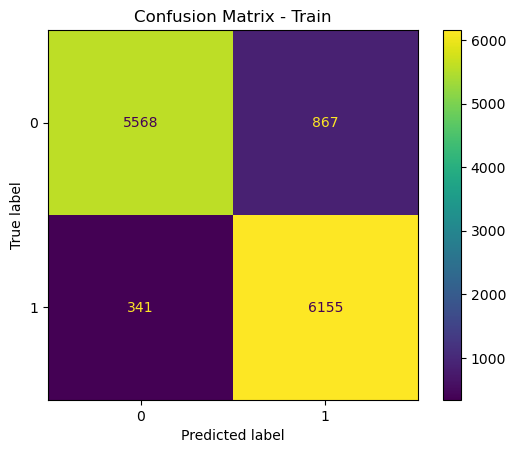


--- TEST METRICS ---
Accuracy: 0.90
Precision: 0.87
Recall: 0.93568726
F1 Score: 0.90


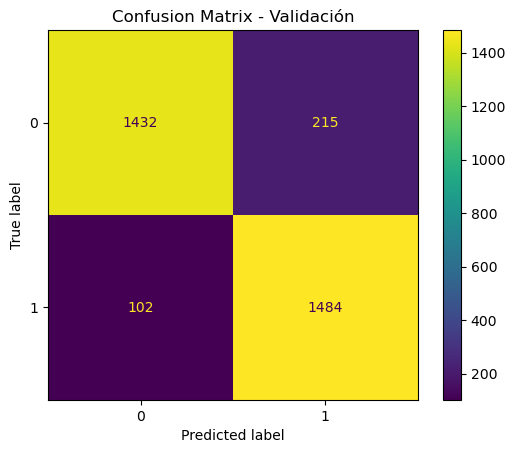

In [17]:
# Entrenamiento
mlp = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation='logistic',
    max_iter=500,
    random_state=42,
    alpha=0.001,
    learning_rate_init=0.1,
    solver='adam'
)
mlp.fit(X_train, y_train)

# Predicciones
y_pred_train = mlp.predict(X_train)
y_pred_val = mlp.predict(X_val)

# Métricas para train
print("\n--- TRAIN METRICS ---")
print(f"Accuracy: {accuracy_score(y_train, y_pred_train):.2f}")
print(f"Precision: {precision_score(y_train, y_pred_train):.2f}")
print(f"Recall: {recall_score(y_train, y_pred_train):.8f}")
print(f"F1 Score: {f1_score(y_train, y_pred_train):.2f}")

# Matriz de confusión - Train
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_train)
plt.title("Confusion Matrix - Train")
plt.show()

# Métricas para val
print("\n--- TEST METRICS ---")
print(f"Accuracy: {accuracy_score(y_val, y_pred_val):.2f}")
print(f"Precision: {precision_score(y_val, y_pred_val):.2f}")
print(f"Recall: {recall_score(y_val, y_pred_val):.8f}")
print(f"F1 Score: {f1_score(y_val, y_pred_val):.2f}")

# Matriz de confusión - val
ConfusionMatrixDisplay.from_predictions(y_val, y_pred_val)
plt.title("Confusion Matrix - Validación")
plt.show()

In [18]:
test_id = PatientId_test
test_pred = np.int64(mlp.predict(X_test))
df_salida_perceptron = pd.DataFrame({'patient': test_id, 'diabetes': test_pred})
df_salida_perceptron.head(5)

,patient,diabetes
0,49267,0
1,82280,1
2,33216,1
3,94551,0
4,43760,1


Este modelo obtuvo una puntuación de recall de 1.000 en la competencia, por lo que se utilizará como parámetro de referencia para evaluar los demás modelos desarrollados, los cuales obtuvieron puntajes inferiores.

## 3. Árboles de decisión

In [19]:
# param_grid = {
#     'criterion': ['gini', 'entropy'],
#     'max_depth': [3, 5, 10, 15, None],
#     'min_samples_split': [2, 5, 10],
#     'min_samples_leaf': [1, 5, 10],
#     'max_features': [None, 'sqrt', 'log2'],
#     'class_weight': [None, 'balanced']
# }

# grid = GridSearchCV(DecisionTreeClassifier(random_state=1), param_grid, cv=5, scoring='recall')
# grid.fit(X_train, y_train)

# print("Mejores parámetros:", grid.best_params_)
# print("Mejor recall en validación cruzada:", grid.best_score_)

Los hiperparámetros que definen al mejor modelo son :
                                                    'class_weight': None, 
                                                    'criterion': 'entropy', 
                                                    'max_depth': 5, 
                                                    'max_features': None, 
                                                    'min_samples_leaf': 1, 
                                                    'min_samples_split': 2


--- TRAIN METRICS ---
Accuracy: 0.89
Precision: 0.84
Recall: 0.95812808
F1 Score: 0.90


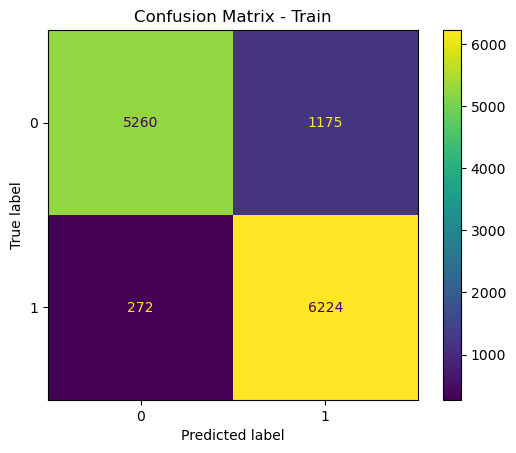


--- VALIDATION METRICS ---
Accuracy: 0.88
Precision: 0.83
Recall: 0.96090794
F1 Score: 0.89


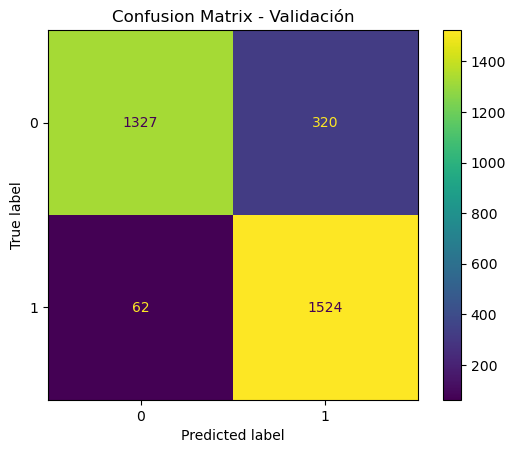

In [20]:
model = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features=None,
    class_weight=None,
    random_state= 1,
)
model.fit(X_train, y_train)

# Predicciones
y_pred_train = model.predict(X_train)
y_pred_val = model.predict(X_val)

# Métricas para train
print("\n--- TRAIN METRICS ---")
print(f"Accuracy: {accuracy_score(y_train, y_pred_train):.2f}")
print(f"Precision: {precision_score(y_train, y_pred_train):.2f}")
print(f"Recall: {recall_score(y_train, y_pred_train):.8f}")
print(f"F1 Score: {f1_score(y_train, y_pred_train):.2f}")

# Matriz de confusión - Train
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_train)
plt.title("Confusion Matrix - Train")
plt.show()

# Métricas para val
print("\n--- VALIDATION METRICS ---")
print(f"Accuracy: {accuracy_score(y_val, y_pred_val):.2f}")
print(f"Precision: {precision_score(y_val, y_pred_val):.2f}")
print(f"Recall: {recall_score(y_val, y_pred_val):.8f}")
print(f"F1 Score: {f1_score(y_val, y_pred_val):.2f}")

# Matriz de confusión - Validación
ConfusionMatrixDisplay.from_predictions(y_val, y_pred_val)
plt.title("Confusion Matrix - Validación")
plt.show()

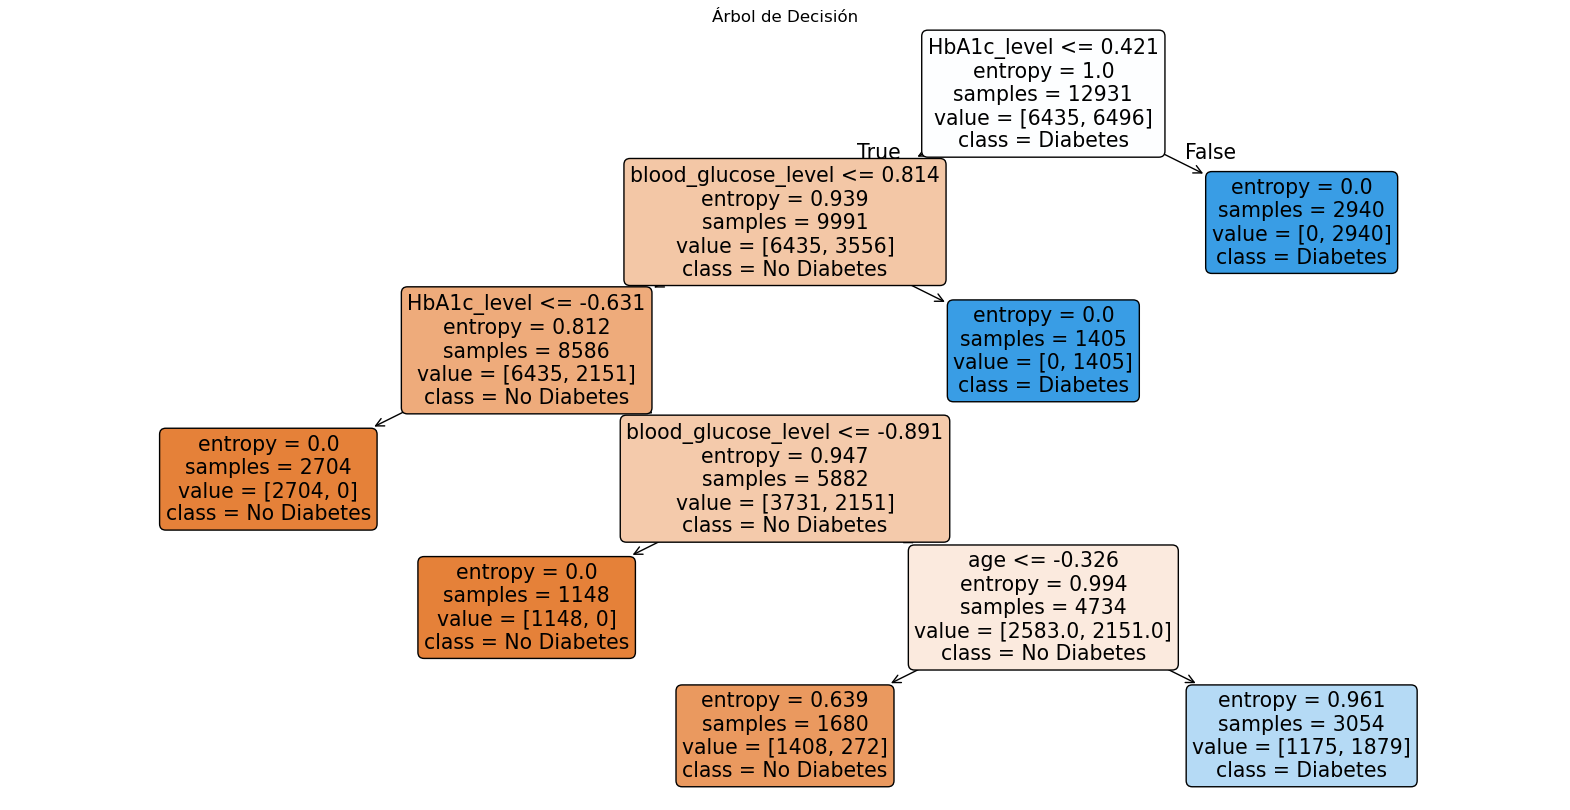

In [21]:
plt.figure(figsize=(20,10))
plot_tree(
    model,
    feature_names=X.columns,
    class_names=['No Diabetes', 'Diabetes'],
    filled=True,
    rounded=True
)
plt.title("Árbol de Decisión")
plt.show()

C:\Users\pc\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


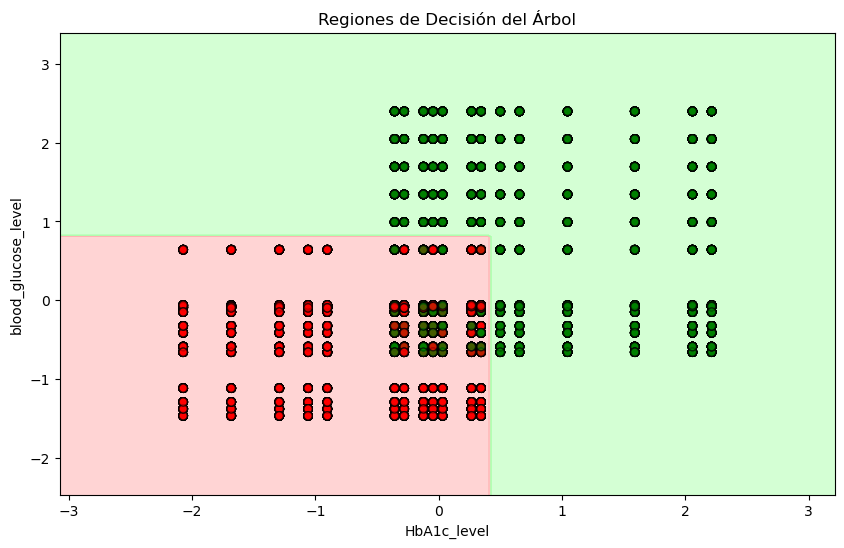

In [22]:
feature1 = 'HbA1c_level'
feature2 = 'blood_glucose_level'

X_plot = X_train[[feature1, feature2]].copy()
y_plot = y_train.copy()

# Árbol entrenado con solo 2 features
model2d = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=5,
    class_weight='balanced',
    random_state=1
)
model2d.fit(X_plot, y_plot)

# Malla para contornos
x_min, x_max = X_plot[feature1].min() - 1, X_plot[feature1].max() + 1
y_min, y_max = X_plot[feature2].min() - 1, X_plot[feature2].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x_min, x_max, 200),
                       np.linspace(y_min, y_max, 200))

Z = model2d.predict(np.c_[xx1.ravel(), xx2.ravel()])
Z = Z.reshape(xx1.shape)

# Fondo con regiones de decisión
plt.figure(figsize=(10, 6))
plt.contourf(xx1, xx2, Z, cmap=ListedColormap(["#FFAAAA", "#AAFFAA"]), alpha=0.5)

# Datos reales sobrepuestos
plt.scatter(X_plot[feature1], X_plot[feature2], c=y_plot, cmap=ListedColormap(["red", "green"]), edgecolor='k', alpha=0.7)

plt.xlabel(feature1)
plt.ylabel(feature2)
plt.title("Regiones de Decisión del Árbol")
plt.show()

In [23]:
y_test_pred = np.int64(model.predict(X_test))
df_salida_arbol = pd.DataFrame({'patient': test_id, 'diabetes': y_test_pred})
df_salida_arbol.head(5)

,patient,diabetes
0,49267,0
1,82280,1
2,33216,1
3,94551,0
4,43760,1



--- COMPARACIÓN Árbol vs Perceptrón
Accuracy:  0.9290
Precision: 0.9020
Recall:    0.9736
F1 Score:  0.9364


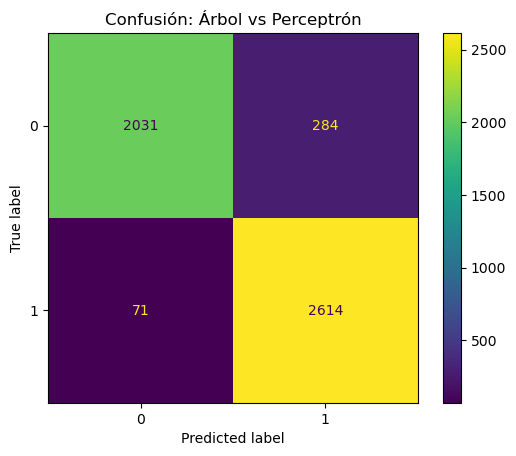

In [24]:
arbol_vs_perceptron = pd.DataFrame({
    'patient': test_id,
    'perceptron': df_salida_perceptron['diabetes'],
    'arbol': df_salida_arbol['diabetes']
})

y_true = arbol_vs_perceptron['perceptron']
y_pred = arbol_vs_perceptron['arbol']

print("\n--- COMPARACIÓN Árbol vs Perceptrón")
print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_true, y_pred):.4f}")

ConfusionMatrixDisplay.from_predictions(y_true, y_pred)
plt.title("Confusión: Árbol vs Perceptrón")
plt.show()

## 4. Random Forest

In [25]:
# param_grid_small = {
#     'n_estimators': [100, 200],
#     'max_depth': [None, 10, 20],
#     'max_features': ['sqrt', 'log2'],
#     'bootstrap': [True]
# }

# rf = RandomForestClassifier(random_state=42)

# grid_search = GridSearchCV(
#     estimator=rf,
#     param_grid=param_grid_small,
#     cv=5,
#     n_jobs=-1,
#     verbose=2
# )

# grid_search.fit(X_train, y_train)

# best_rf = grid_search.best_estimator_

# y_val_pred = best_rf.predict(X_val)

# print(classification_report(y_val, y_val_pred))

# recall_val = recall_score(y_val, y_val_pred)
# print(f"Recall test Random Forest: {recall_val * 100:.2f}%")

# recall_train = recall_score(y_train, best_rf.predict(X_train))
# print(f"Recall train Random Forest: {recall_train * 100:.2f}%")

#Buscados previamente
optimal_parameters_rf = {
    'n_estimators': 200,
    'max_depth': 20,
    'max_features': 'sqrt',
    'bootstrap': True,
    'random_state': 4
}

Los hiperparámetros que definen al mejor modelo de Random Forest son:
n_estimators: 200, max_depth: 20, max_features: 'sqrt', bootstrap: True, random_state: 42.


--- TRAIN METRICS ---
Accuracy: 1.00
Precision: 1.00
Recall: 0.99892241
F1 Score: 1.00


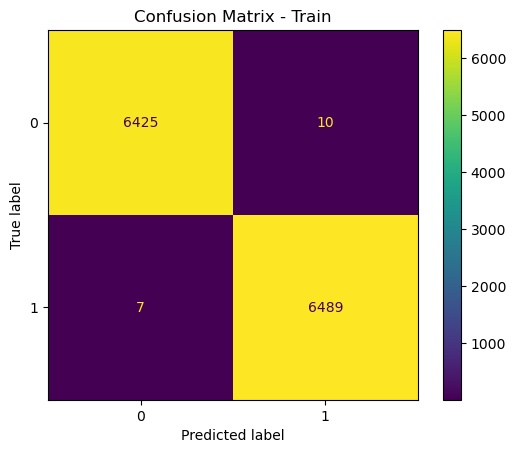


--- VALIDATION METRICS ---
Accuracy: 0.90
Precision: 0.90
Recall: 0.90037831
F1 Score: 0.90


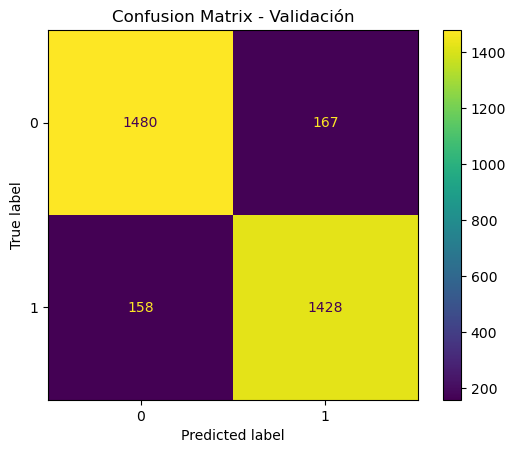

In [26]:
model = RandomForestClassifier(**optimal_parameters_rf)
model.fit(X_train, y_train)

# Predicciones
y_pred_train = model.predict(X_train)
y_pred_val = model.predict(X_val)

# Métricas para train
print("\n--- TRAIN METRICS ---")
print(f"Accuracy: {accuracy_score(y_train, y_pred_train):.2f}")
print(f"Precision: {precision_score(y_train, y_pred_train):.2f}")
print(f"Recall: {recall_score(y_train, y_pred_train):.8f}")
print(f"F1 Score: {f1_score(y_train, y_pred_train):.2f}")

# Matriz de confusión - Train
ConfusionMatrixDisplay.from_predictions(y_train, y_pred_train)
plt.title("Confusion Matrix - Train")
plt.show()

# Métricas para val
print("\n--- VALIDATION METRICS ---")
print(f"Accuracy: {accuracy_score(y_val, y_pred_val):.2f}")
print(f"Precision: {precision_score(y_val, y_pred_val):.2f}")
print(f"Recall: {recall_score(y_val, y_pred_val):.8f}")
print(f"F1 Score: {f1_score(y_val, y_pred_val):.2f}")

# Matriz de confusión - Validación
ConfusionMatrixDisplay.from_predictions(y_val, y_pred_val)
plt.title("Confusion Matrix - Validación")
plt.show()

In [27]:
y_test_pred = np.int64(model.predict(X_test))
df_salida_randomforest = pd.DataFrame({
    'patient': test_id,
    'diabetes': y_test_pred
})

df_salida_randomforest.head(5)

,patient,diabetes
0,49267,0
1,82280,1
2,33216,1
3,94551,0
4,43760,1



--- COMPARACIÓN Random Forest vs Perceptrón
Accuracy:  0.9342
Precision: 0.9299
Recall:    0.9490
F1 Score:  0.9394


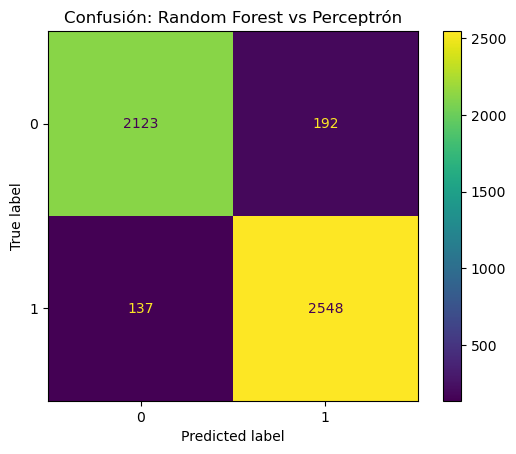

In [28]:
rf_vs_perceptron = pd.DataFrame({
    'patient': test_id,
    'perceptron': df_salida_perceptron['diabetes'],
    'randomforest': df_salida_randomforest['diabetes']
})

y_true = rf_vs_perceptron['perceptron']
y_pred = rf_vs_perceptron['randomforest']

print("\n--- COMPARACIÓN Random Forest vs Perceptrón")
print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_true, y_pred):.4f}")

ConfusionMatrixDisplay.from_predictions(y_true, y_pred)
plt.title("Confusión: Random Forest vs Perceptrón")
plt.show()

## 5.XGBoost

In [29]:
# param_grid = {
#     "max_depth": [3, 6, 9],
#     "min_child_weight": [1, 5, 10],
#     "gamma": [0, 0.1, 0.5],
#     "subsample": [0.6, 0.8, 1.0],
#     "colsample_bytree": [0.6, 0.8, 1.0],
#     "learning_rate": [0.01, 0.1, 0.3],
#     "reg_lambda": [1, 5, 10],
#     "reg_alpha": [0, 1, 5]
# }

# grid = GridSearchCV(
#     XGBClassifier(eval_metric=['logloss', 'auc', 'error'], n_jobs=-1, use_label_encoder=False, random_state=42),
#     param_grid,
#     cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
#     scoring='recall',
#     verbose=2,
#     error_score='raise'
# )

# grid.fit(X_train, y_train)

# # Print recall for each parameter combination during search
# means = grid.cv_results_['mean_test_score']
# stds = grid.cv_results_['std_test_score']
# params = grid.cv_results_['params']

# for mean, std, param in zip(means, stds, params):
#     print(f"Recall: {mean:.4f} (+/-{std:.4f}) for {param}")

# # Mostrar los mejores hiperparámetros
# print("\nMejores hiperparámetros encontrados:")
# print(grid.best_params_)

Los hiperparámetros que definen al mejor modelo de XGBoost son:
colsample_bytree: 1.0, gamma: 0, learning_rate: 0.01, max_depth: 6, min_child_weight: 5, n_estimators: 200, reg_alpha: 5, reg_lambda: 1, subsample: 0.8.

C:\Users\pc\anaconda3\Lib\site-packages\xgboost\training.py:183: UserWarning: [20:53:49] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)



--- TRAIN METRICS ---
Accuracy:  0.90
Precision: 0.88
Recall:    0.94365764
F1 Score:  0.91


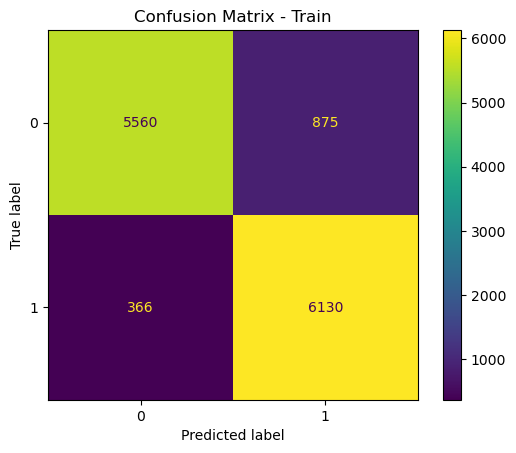


--- VALIDATION METRICS ---
Accuracy:  0.90
Precision: 0.87
Recall:    0.93820933
F1 Score:  0.90


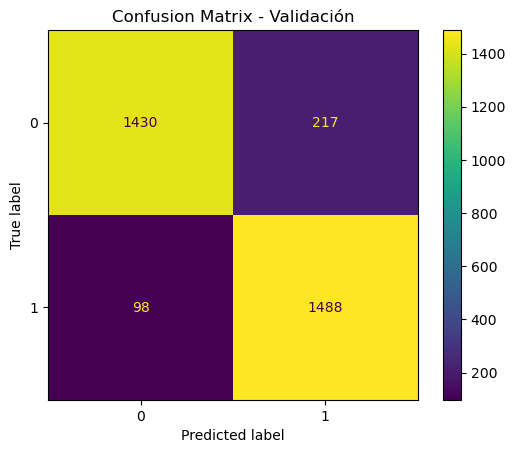

In [30]:
optimal_parameters = {
    'colsample_bytree': 1.0,
    'gamma': 0,
    'learning_rate': 0.01,
    'max_depth': 6,
    'min_child_weight': 5,
    'n_estimators': 200,
    'reg_alpha': 5,
    'reg_lambda': 1,
    'subsample': 0.8
}

model = XGBClassifier(**optimal_parameters, use_label_encoder=False, eval_metric='logloss', random_state=42)
model.fit(X_train, y_train)

# Predicciones
y_pred_train = model.predict(X_train)
y_pred_val = model.predict(X_val)

# Métricas para train
print("\n--- TRAIN METRICS ---")
print(f"Accuracy:  {accuracy_score(y_train, y_pred_train):.2f}")
print(f"Precision: {precision_score(y_train, y_pred_train):.2f}")
print(f"Recall:    {recall_score(y_train, y_pred_train):.8f}")
print(f"F1 Score:  {f1_score(y_train, y_pred_train):.2f}")

ConfusionMatrixDisplay.from_predictions(y_train, y_pred_train)
plt.title("Confusion Matrix - Train")
plt.show()

# Métricas para validación
print("\n--- VALIDATION METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_val):.2f}")
print(f"Precision: {precision_score(y_val, y_pred_val):.2f}")
print(f"Recall:    {recall_score(y_val, y_pred_val):.8f}")
print(f"F1 Score:  {f1_score(y_val, y_pred_val):.2f}")

ConfusionMatrixDisplay.from_predictions(y_val, y_pred_val)
plt.title("Confusion Matrix - Validación")
plt.show()

In [31]:
df_salida_xgboost = pd.DataFrame({
    'patient': test_id,
    'diabetes': test_pred
})

df_salida_xgboost.head(5)

,patient,diabetes
0,49267,0
1,82280,1
2,33216,1
3,94551,0
4,43760,1



--- COMPARACIÓN XGBoost vs Perceptrón
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000


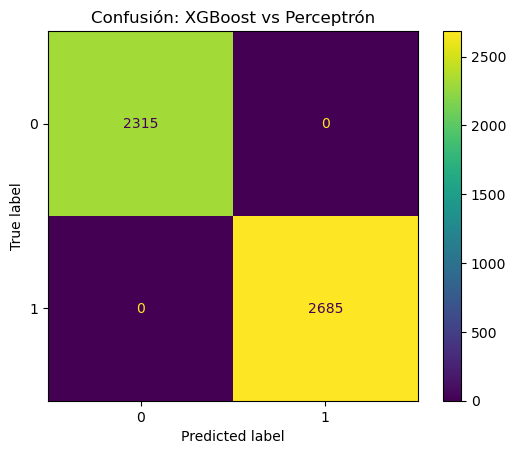

In [32]:
xgb_vs_perceptron = pd.DataFrame({
    'patient': test_id,
    'perceptron': df_salida_perceptron['diabetes'],
    'xgboost': df_salida_xgboost['diabetes']
})

y_true = xgb_vs_perceptron['perceptron']
y_pred = xgb_vs_perceptron['xgboost']

print("\n--- COMPARACIÓN XGBoost vs Perceptrón")
print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_true, y_pred):.4f}")

ConfusionMatrixDisplay.from_predictions(y_true, y_pred)
plt.title("Confusión: XGBoost vs Perceptrón")
plt.show()

## 6. Support Vector Machine

In [33]:
# svm = SVC(random_state=42)

# grid_svm = GridSearchCV(
#     estimator=svm,
#     param_grid=param_grid_svm,
#     cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
#     scoring='recall',
#     n_jobs=-1,
#     verbose=2
# )

# grid_svm.fit(X_train, y_train)

La mejor combinación de hiperparámetros para el modelo SVM es:
kernel = linear, C = 1.0.


--- TRAIN METRICS ---
Accuracy:  0.88
Precision: 0.88
Recall:    0.88577586
F1 Score:  0.89


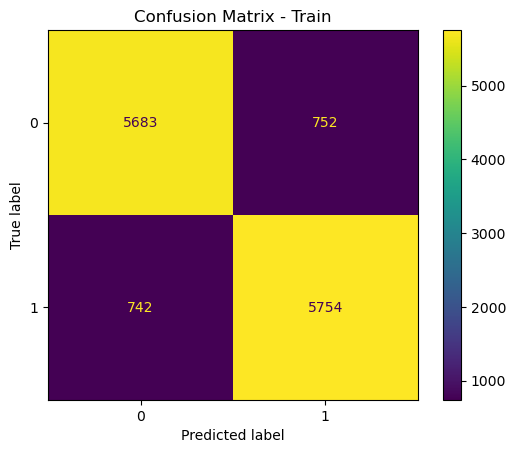


--- VALIDATION METRICS ---
Accuracy:  0.88
Precision: 0.88
Recall:    0.88020177
F1 Score:  0.88


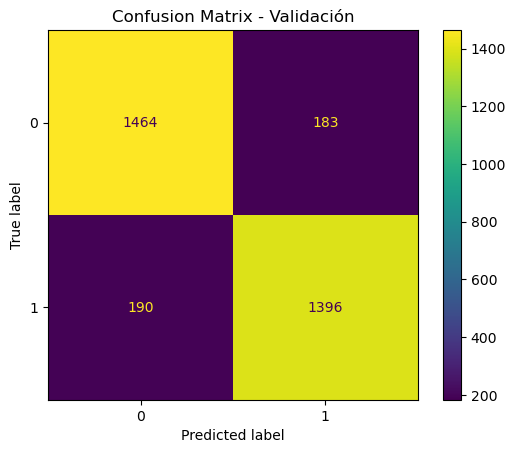

In [34]:
model = SVC(kernel='linear', C=1.0, random_state=42)
model.fit(X_train, y_train)

# Predicciones
y_pred_train = model.predict(X_train)
y_pred_val = model.predict(X_val)

# Métricas para train
print("\n--- TRAIN METRICS ---")
print(f"Accuracy:  {accuracy_score(y_train, y_pred_train):.2f}")
print(f"Precision: {precision_score(y_train, y_pred_train):.2f}")
print(f"Recall:    {recall_score(y_train, y_pred_train):.8f}")
print(f"F1 Score:  {f1_score(y_train, y_pred_train):.2f}")

ConfusionMatrixDisplay.from_predictions(y_train, y_pred_train)
plt.title("Confusion Matrix - Train")
plt.show()

# Métricas para validación
print("\n--- VALIDATION METRICS ---")
print(f"Accuracy:  {accuracy_score(y_val, y_pred_val):.2f}")
print(f"Precision: {precision_score(y_val, y_pred_val):.2f}")
print(f"Recall:    {recall_score(y_val, y_pred_val):.8f}")
print(f"F1 Score:  {f1_score(y_val, y_pred_val):.2f}")

ConfusionMatrixDisplay.from_predictions(y_val, y_pred_val)
plt.title("Confusion Matrix - Validación")
plt.show()

In [35]:
test_pred = model.predict(X_test)
test_pred = test_pred.astype(int)

df_salida_svm = pd.DataFrame({
    'patient': test_id,
    'diabetes': test_pred
})

df_salida_svm.head(5)

,patient,diabetes
0,49267,0
1,82280,1
2,33216,1
3,94551,0
4,43760,1



--- COMPARACIÓN SVM vs Perceptrón
Accuracy:  0.8524
Precision: 0.8896
Recall:    0.8279
F1 Score:  0.8576


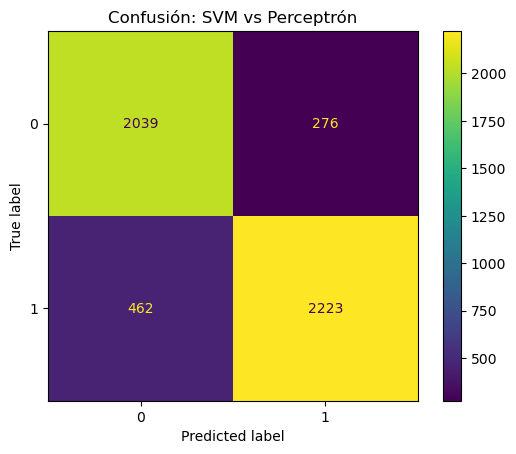

In [36]:
svm_vs_perceptron = pd.DataFrame({
    'patient': test_id,
    'perceptron': df_salida_perceptron['diabetes'],
    'svm': df_salida_svm['diabetes']
})

y_true = svm_vs_perceptron['perceptron']
y_pred = svm_vs_perceptron['svm']

print("\n--- COMPARACIÓN SVM vs Perceptrón")
print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred):.4f}")
print(f"F1 Score:  {f1_score(y_true, y_pred):.4f}")

ConfusionMatrixDisplay.from_predictions(y_true, y_pred)
plt.title("Confusión: SVM vs Perceptrón")
plt.show()

## 7. Conclusión

In [37]:
model_outputs = {
    'Perceptron': df_salida_perceptron['diabetes'],
    'Árbol': df_salida_arbol['diabetes'],
    'RandomForest': df_salida_randomforest['diabetes'],
    'XGBoost': df_salida_xgboost['diabetes'],
    'SVM': df_salida_svm['diabetes']
}

y_true = df_salida_perceptron['diabetes']

metrics_dict = {
    'Modelo': [],
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1 Score': []
}

for model_name, y_pred in model_outputs.items():
    metrics_dict['Modelo'].append(model_name)
    metrics_dict['Accuracy'].append(accuracy_score(y_true, y_pred))
    metrics_dict['Precision'].append(precision_score(y_true, y_pred))
    metrics_dict['Recall'].append(recall_score(y_true, y_pred))
    metrics_dict['F1 Score'].append(f1_score(y_true, y_pred))

df_comparativo = pd.DataFrame(metrics_dict)

df_comparativo = df_comparativo.sort_values(by='Recall', ascending=False).reset_index(drop=True)
print(df_comparativo)

         Modelo  Accuracy  Precision    Recall  F1 Score
0    Perceptron    1.0000   1.000000  1.000000  1.000000
1       XGBoost    1.0000   1.000000  1.000000  1.000000
2         Árbol    0.9290   0.902001  0.973557  0.936414
3  RandomForest    0.9342   0.929927  0.948976  0.939355
4           SVM    0.8524   0.889556  0.827933  0.857639


El recall, también llamado sensibilidad o tasa de verdaderos positivos, es una métrica que mide qué tan bien un modelo detecta los casos positivos reales. Matemáticamente, se define como la proporción de verdaderos positivos sobre la suma de verdaderos positivos y falsos negativos. En otras palabras, indica qué porcentaje de los casos que realmente son positivos, como pacientes con diabetes, el modelo logra identificar correctamente. Se utiliza esta métrica en particular porque en problemas donde la clase positiva es crítica, como en detección de enfermedades, es más importante minimizar los falsos negativos que los falsos positivos. Un recall alto significa que el modelo logra captar la mayoría de los casos positivos, lo cual es fundamental en contextos médicos aunque se sacrifique algo de precisión. En este análisis, los valores de recall obtenidos fueron: Perceptrón y XGBoost con 1.0000, Árbol de decisión con 0.9736, Random Forest con 0.9490 y SVM con 0.8279.